In [1]:
import pandas as pd

In [2]:
df = pd.read_csv("data/preprocesados/merge1.csv")
df = df.drop(["GENOTYPE", "APOE4CARRIER", "TOTSCORE", "CDGLOBAL", "image_id", "subject_id", "series_description"], axis=1)

df["VISDATE_DIAG"] = pd.to_datetime(df["VISDATE_DIAG"], errors="coerce")
df["PTDOB"] = pd.to_datetime(df["PTDOB"], errors="coerce")

df["AGE"] = ((df["VISDATE_DIAG"] - df["PTDOB"]).dt.days / 365.25).round(3)
df["PTGENDER"] = df["PTGENDER"].map({2: 0, 1: 1}) # hombre 1 mujer 0
df["DIAGNOSIS"] = df["DIAGNOSIS"].map({1: 0, 2: 1, 3: 2}) # cn 0, mci 1, ad 2

df_t0 = df[df["VISCODE2"] == "bl"][["RID","PTGENDER","AGE","PTEDUCAT","APOE4CONT","DIAGNOSIS","MMSCORE","TOTAL13","CDRSB",]]
df_t0 = df_t0.rename(columns={"AGE": "AGE_T0","MMSCORE": "MMSCORE_T0","TOTAL13": "TOTAL13_T0","CDRSB": "CDRSB_T0", "DIAGNOSIS":"DIAGNOSIS_T0"})

df_t1 = df[df["VISCODE2"] == "m12"][["RID", "DIAGNOSIS", "MMSCORE", "TOTAL13", "CDRSB"]]
df_t1 = df_t1.rename(columns={"MMSCORE": "MMSCORE_T1","TOTAL13": "TOTAL13_T1","CDRSB": "CDRSB_T1", "DIAGNOSIS":"DIAGNOSIS_T1"})

df_t2 = df[df["VISCODE2"] == "m24"][["RID", "MMSCORE", "TOTAL13", "CDRSB", "DIAGNOSIS"]]
df_t2 = df_t2.rename(columns={"MMSCORE": "MMSCORE_T2","TOTAL13": "TOTAL13_T2","CDRSB": "CDRSB_T2","DIAGNOSIS": "DIAGNOSIS_T2",})

df_ancho = df_t0.merge(df_t1, on="RID", how="inner")
df_ancho = df_ancho.merge(df_t2, on="RID", how="inner")

df_ancho["DELTA_MMSCORE"] = df_ancho["MMSCORE_T1"] - df_ancho["MMSCORE_T0"]
df_ancho["DELTA_TOTAL13"] = df_ancho["TOTAL13_T1"] - df_ancho["TOTAL13_T0"]
df_ancho["DELTA_CDRSB"] = df_ancho["CDRSB_T1"] - df_ancho["CDRSB_T0"]

df = df_ancho.copy()

In [3]:
df.to_csv("data/preprocesados/merge_clean.csv")

---

In [4]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    mean_absolute_error,
    root_mean_squared_error,
    r2_score,
    roc_auc_score,
)
from sklearn.model_selection import KFold, StratifiedKFold, cross_val_predict
from sklearn.multioutput import MultiOutputRegressor
from xgboost import XGBRegressor

In [5]:
feature_cols = [
    "PTGENDER",
    "AGE_T0",
    "PTEDUCAT",
    "APOE4CONT",
    "DIAGNOSIS_T0",
    "DIAGNOSIS_T1",
    "MMSCORE_T0",
    "TOTAL13_T0",
    "CDRSB_T0",
    "MMSCORE_T1",
    "TOTAL13_T1",
    "CDRSB_T1",
    "DELTA_MMSCORE",
    "DELTA_TOTAL13",
    "DELTA_CDRSB",
]
target_cols = ["MMSCORE_T2", "TOTAL13_T2", "CDRSB_T2"]

X = df[feature_cols].values
y_scores = df[target_cols].values
y_diag = df["DIAGNOSIS_T2"].values

TESTS = ["MMSE", "ADAS13", "CDRSB"]
CLASES = ["CN", "MCI", "AD"]

In [6]:
models = {
    "LinearRegression": LinearRegression(),
    "RandomForestRegressor": RandomForestRegressor(
        n_estimators=100, random_state=42, n_jobs=-1
    ),
    "XGBRegressor": MultiOutputRegressor(
        XGBRegressor(
            n_estimators=100,
            learning_rate=0.05,
            max_depth=4,
            random_state=42,
            n_jobs=-1,
        )
    ),
}

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [7]:
import json

# Generar y exportar la partición por paciente (RID)
folds = {}

for fold, (train_idx, val_idx) in enumerate(skf.split(X, y_diag)):
    folds[f"fold_{fold}"] = {
        "train_rids": [int(rid) for rid in df.iloc[train_idx]["RID"]],
        "val_rids": [int(rid) for rid in df.iloc[val_idx]["RID"]],
    }

with open("data/preprocesados/cv_splits_rids.json", "w") as f:
    json.dump(folds, f, indent=4)

In [8]:
with open("data/preprocesados/cv_splits_rids.json", "r") as f:
    folds = json.load(f)

metricas_regresion = []
metricas_clasificacion = []
informe_clases = {}
cms = {}

for name, model in models.items():
    fold_mae = []
    fold_rmse = []
    fold_r2 = []
    fold_acc = []
    fold_bal_acc = []
    fold_f1 = []

    y_true_list = []
    y_pred_list = []
    y_prob_list = []

    for fold, data in folds.items():
        train_mask = df["RID"].isin(data["train_rids"]).values
        val_mask = df["RID"].isin(data["val_rids"]).values

        X_train = X[train_mask]
        X_val = X[val_mask]
        y_scores_train = y_scores[train_mask]
        y_scores_val = y_scores[val_mask]
        y_diag_train = y_diag[train_mask]
        y_diag_val = y_diag[val_mask]

        fold_model = clone(model).fit(X_train, y_scores_train)
        pred_scores = fold_model.predict(X_val)

        fold_mae.append(mean_absolute_error(y_scores_val, pred_scores, multioutput="raw_values"))
        fold_rmse.append(root_mean_squared_error(y_scores_val, pred_scores, multioutput="raw_values"))
        fold_r2.append(r2_score(y_scores_val, pred_scores, multioutput="raw_values"))

        kf = KFold(n_splits=5, shuffle=True, random_state=42)
        oof_scores_train = cross_val_predict(clone(model), X_train, y_scores_train, cv=kf, method="predict", n_jobs=-1)

        clf = LogisticRegression(max_iter=1000, random_state=42)
        clf.fit(oof_scores_train, y_diag_train)

        pred_val = clf.predict(pred_scores)
        prob_val = clf.predict_proba(pred_scores)

        fold_acc.append(accuracy_score(y_diag_val, pred_val))
        fold_bal_acc.append(balanced_accuracy_score(y_diag_val, pred_val))
        fold_f1.append(f1_score(y_diag_val, pred_val, average="macro"))

        y_true_list.append(y_diag_val)
        y_pred_list.append(pred_val)
        y_prob_list.append(prob_val)

    y_true = np.concatenate(y_true_list)
    y_pred = np.concatenate(y_pred_list)
    y_prob = np.concatenate(y_prob_list)

    cms[name] = confusion_matrix(y_true, y_pred)

    mae_mean, mae_std = np.mean(fold_mae, axis=0), np.std(fold_mae, axis=0)
    rmse_mean, rmse_std = np.mean(fold_rmse, axis=0), np.std(fold_rmse, axis=0)
    r2_mean, r2_std = np.mean(fold_r2, axis=0), np.std(fold_r2, axis=0)

    reg = {"Modelo": name}
    for i, test in enumerate(TESTS):
        reg[f"{test} MAE"] = f"{mae_mean[i]:.2f} ± {mae_std[i]:.2f}"
        reg[f"{test} RMSE"] = f"{rmse_mean[i]:.2f} ± {rmse_std[i]:.2f}"
        reg[f"{test} R2"] = f"{r2_mean[i]:.3f} ± {r2_std[i]:.3f}"
    metricas_regresion.append(reg)

    auc_roc = roc_auc_score(y_true, y_prob, multi_class="ovr", average="macro")

    metricas_clasificacion.append({
        "Modelo": name,
        "Accuracy": f"{np.mean(fold_acc)*100:.1f}% ± {np.std(fold_acc)*100:.1f}%",
        "Balanced Acc": f"{np.mean(fold_bal_acc)*100:.1f}% ± {np.std(fold_bal_acc)*100:.1f}%",
        "F1 (Macro)": f"{np.mean(fold_f1):.3f} ± {np.std(fold_f1):.3f}",
        "AUC-ROC": f"{auc_roc:.3f}",
    })

    informe = classification_report(y_true, y_pred, target_names=CLASES, digits=3, output_dict=True)
    informe = pd.DataFrame(informe).transpose().iloc[:3, :3]  # Filas CN, MCI, AD
    informe["auc_roc"] = [roc_auc_score(y_true == i, y_prob[:, i]) for i in range(3)]
    informe_clases[name] = informe

In [9]:
df_regresion = pd.DataFrame(metricas_regresion).set_index("Modelo")
df_global = pd.DataFrame(metricas_clasificacion).set_index("Modelo")
df_informe = pd.concat(informe_clases).round(3)
df_informe.index.names = ["Modelo", "Diagnóstico"]

print("\n" + "=" * 80)
print("1. EVALUACIÓN DE REGRESIÓN COGNITIVA (MAE, RMSE, R2 por Test)")
print("=" * 80)
print(df_regresion.to_string())

print("\n" + "=" * 80)
print("2. COMPARATIVA GLOBAL DE DIAGNÓSTICO (T2)")
print("=" * 80)
print(df_global.to_string())

print("\n" + "=" * 80)
print("DESGLOSE CLÍNICO POR ENFERMEDAD (LOS 3 MODELOS)")
print("=" * 80)
print(df_informe.to_string())


1. EVALUACIÓN DE REGRESIÓN COGNITIVA (MAE, RMSE, R2 por Test)
                          MMSE MAE    MMSE RMSE        MMSE R2   ADAS13 MAE  ADAS13 RMSE      ADAS13 R2    CDRSB MAE   CDRSB RMSE       CDRSB R2
Modelo                                                                                                                                          
LinearRegression       1.42 ± 0.14  1.95 ± 0.18  0.734 ± 0.051  3.25 ± 0.14  4.48 ± 0.19  0.842 ± 0.009  0.67 ± 0.04  1.04 ± 0.12  0.822 ± 0.031
RandomForestRegressor  1.47 ± 0.09  2.05 ± 0.17  0.705 ± 0.049  3.36 ± 0.20  4.59 ± 0.33  0.834 ± 0.018  0.78 ± 0.04  1.21 ± 0.11  0.758 ± 0.032
XGBRegressor           1.42 ± 0.07  1.98 ± 0.14  0.726 ± 0.038  3.33 ± 0.15  4.63 ± 0.32  0.832 ± 0.015  0.68 ± 0.08  1.12 ± 0.16  0.794 ± 0.039

2. COMPARATIVA GLOBAL DE DIAGNÓSTICO (T2)
                           Accuracy  Balanced Acc     F1 (Macro) AUC-ROC
Modelo                                                                  
LinearRegression       

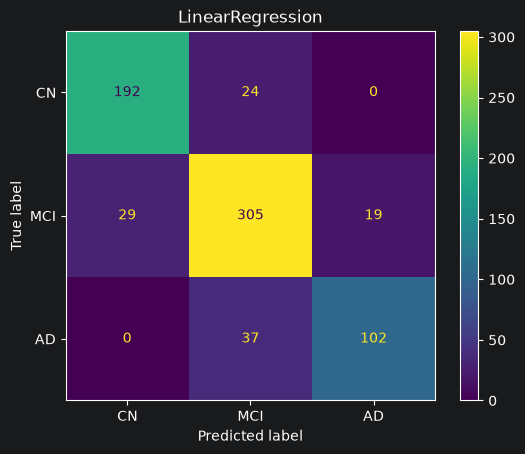

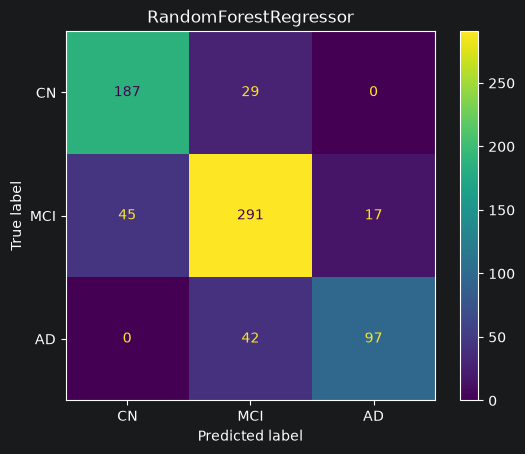

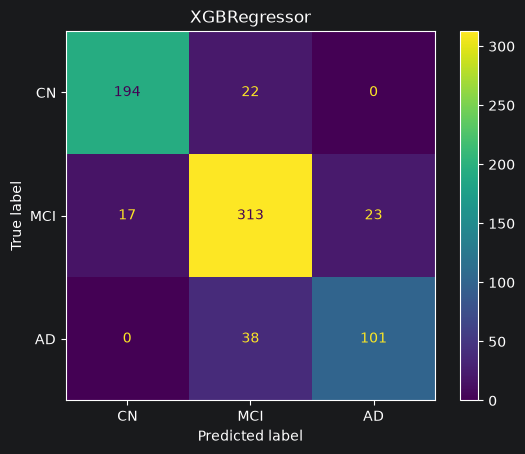

In [10]:
for name, cm in cms.items():
  ConfusionMatrixDisplay(cm, display_labels=CLASES).plot()
  plt.title(name)
  plt.show()